# 03. Gabor filter bank

Gabor filters respond to texture at one scale and orientation. The bank's energy minus its local average is the anomaly: places where the weave texture changes. Good for directional defects.

Method: `filters.py` (`METHOD_NAME = "gabor_bank"`). Evaluation: `evaluate.py`, same rules for every experiment (README section 7): threshold from `good_cal` only, false alarms on unseen `good_test` strips and on hard negatives, recall on defect tiles. Per-tile scores and the cal/test split are saved to `results/gabor_bank/`.

In [1]:
import sys, importlib

sys.path.insert(0, "../src/methods")
import filters as F    # all filters and methods
import evaluate as E   # shared evaluation (README section 7)
importlib.reload(F); importlib.reload(E)  # pick up edits without restarting the kernel

# ---- evaluation settings (same for every experiment) ----------------------
FABRIC = "02"           # fabric code = third part of the file name
METHOD_NAME = "gabor_bank"  # results go to results/<METHOD_NAME>/
THR_K = 4.0             # threshold = median + THR_K x 1.4826 x MAD of good_cal scores
MIN_AREA = 4            # damage mask: drop spots smaller than this (px); keep <= 4
SCORE_K = 25            # tile score = mean of the SCORE_K highest values of the smoothed map
SCORE_SIGMA = 2.0       # smoothing before scoring (px)
NORMALIZE = True        # score = strongest spot / the tile's own typical level (removes strip-to-strip bias)
SETTINGS = dict(thr_k=THR_K, min_area=MIN_AREA, score_k=SCORE_K, score_sigma=SCORE_SIGMA,
                normalize=NORMALIZE)

# ---- method settings -------------------------------------------------------
STEPS = F.DEFAULT_STEPS
LAMBDAS = (6, 10)         # wavelengths (px), around the weave period
N_ORIENT = 4              # number of orientations
BG_SIGMA = 15             # local average of the filter energy
KERNELS = F.gabor_kernels(lambdas=LAMBDAS, n_orient=N_ORIENT)


def method(tile):
    return F.gabor_bank(tile, STEPS, kernels=KERNELS, bg_sigma=BG_SIGMA)


fit = None

## Results for one fabric

In [2]:
res = E.evaluate(method, FABRIC, fit=fit, **SETTINGS)
assert res is not None, f"not enough tiles for fabric {FABRIC}"
S = E.summarize(res)
E.print_summary(res, S)
print("saved to", E.save_results(res, METHOD_NAME))

fabric 02: good_cal 140 tiles (10 strips), good_test 140 tiles (10 strips), 507 hard negatives, 38 defect tiles (0 background tiles skipped)
tile threshold 6.48   pixel threshold 6.48

                    predicted OK   predicted DAMAGED
good + hard neg.             640                   7
defect                        24                  14

false alarm rate    0.0% good_test, 1.4% hard negatives
recall              36.8%  (small <50 px: 39.1% of 23, large: 33.3% of 15)
strip level         false alarm 0.0% of 10 good strips, recall 36.8% of 38 defect strips
precision           66.7%
F1                  0.475
AUROC               0.893   (threshold-free ranking quality)
mean IoU            0.106 over all defect tiles, 0.249 over detected ones
time                33.2 ms/tile (median)
saved to C:\Users\chanupa.d\Documents\concord\fabric inspection\results\gabor_bank


### Score distribution and ROC curve
Left: tile scores with the threshold. Right: recall vs false alarm rate for every possible threshold; the dot is the threshold chosen from good_cal. The curve uses test tiles and is for analysis only.

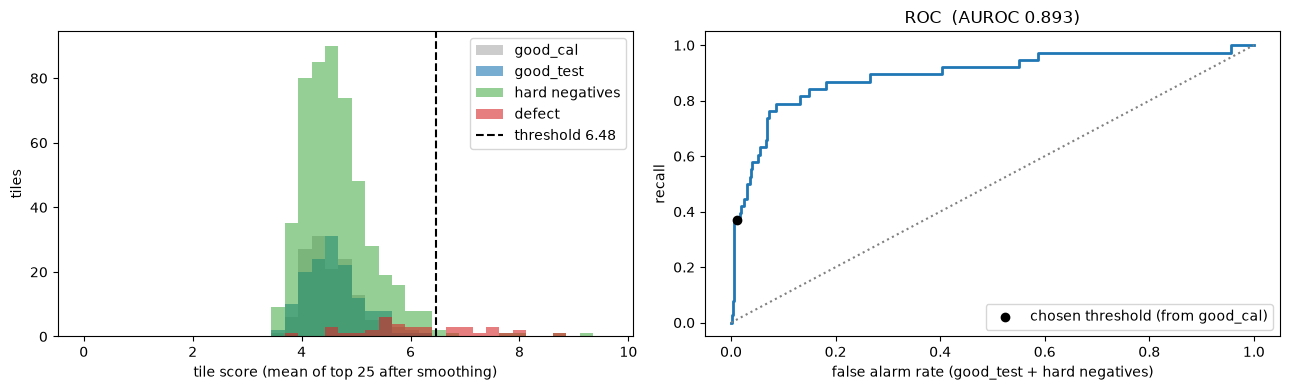

In [3]:
E.plot_scores_roc(res, S)

### Recall per defect type

In [4]:
E.print_by_type(res)

defect   tiles  found   recall  mean IoU  median area  median score
002          1      0       0%      0.00          151          6.15
006          7      3      43%      0.01         1260          5.73
019         23      8      35%      0.11           15          5.98
023          3      1      33%      0.00          778          4.48
030          4      2      50%      0.34           70          6.80


### Failure cases
Missed defects (lowest-scoring defect tiles) and false alarms (highest-scoring good_test / hard-negative tiles). Red = detected, green = ground-truth mask.

24 missed defects, 7 false alarms


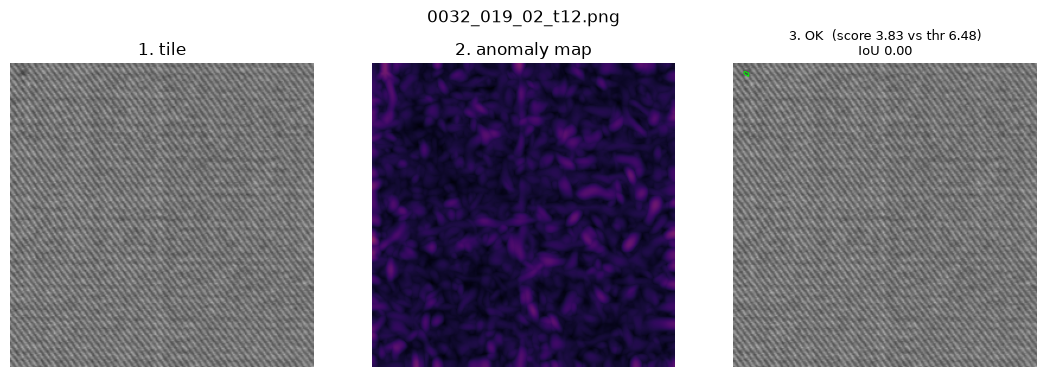

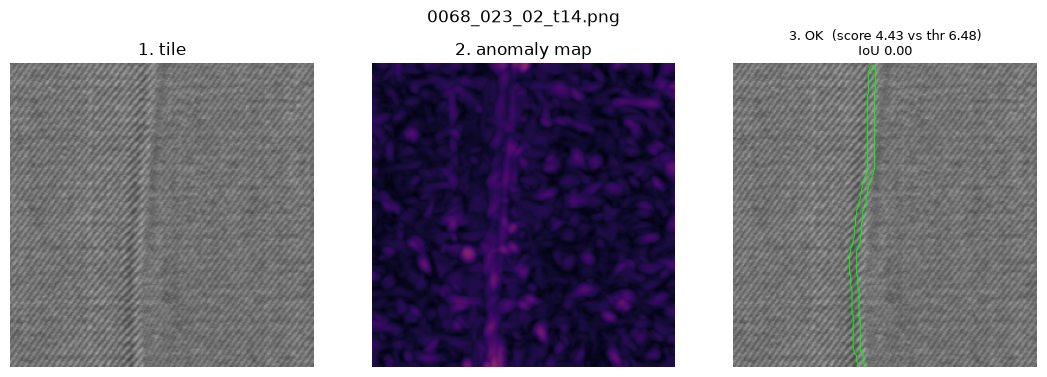

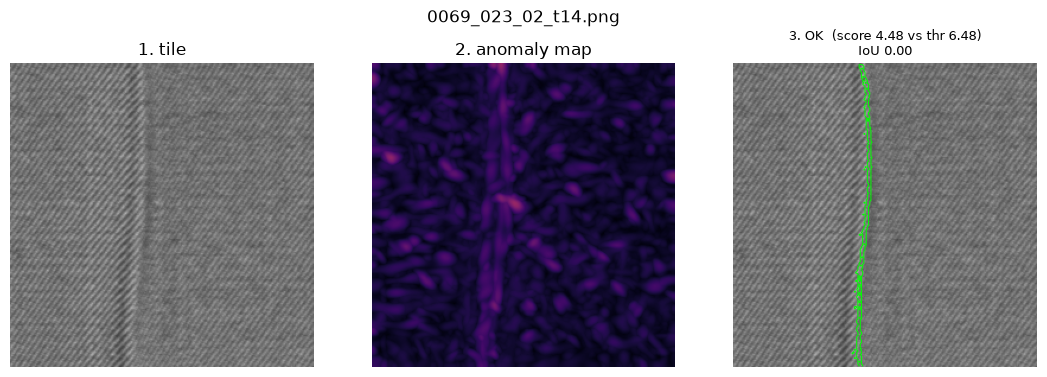

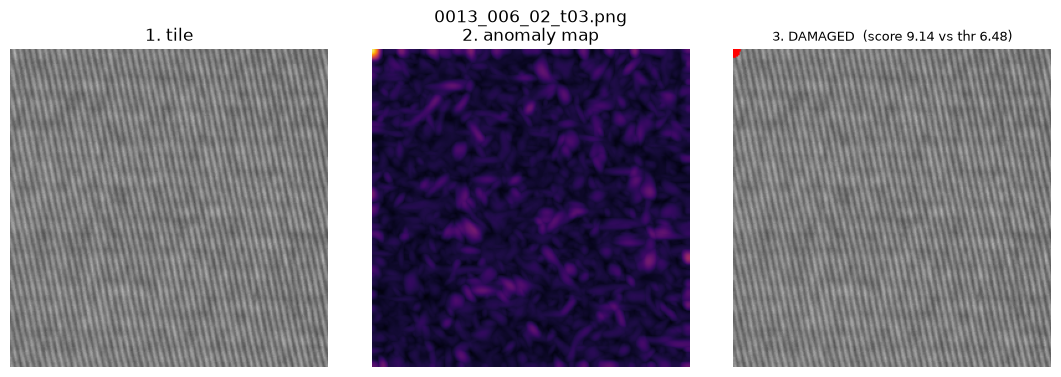

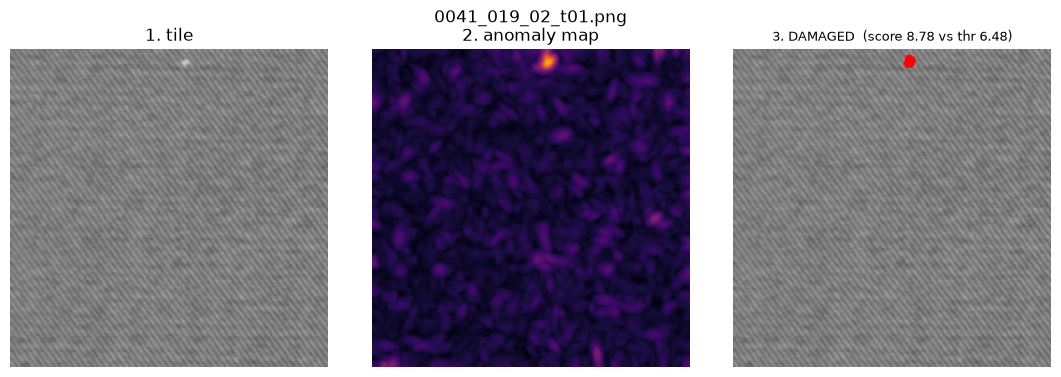

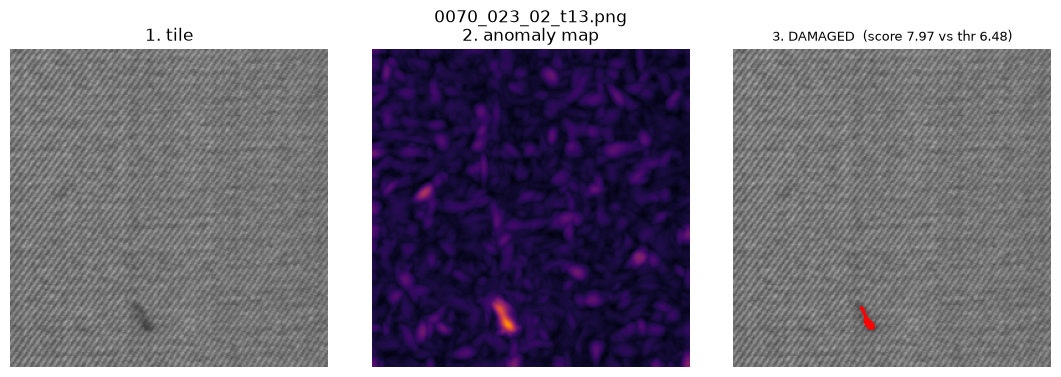

In [5]:
E.show_failures(res, n=3)

### Example tiles
Largest defect, smallest defect (by mask area) and the last good tile of `FABRIC`.

largest defect: 0016_006_02_t12.png, 2111 px


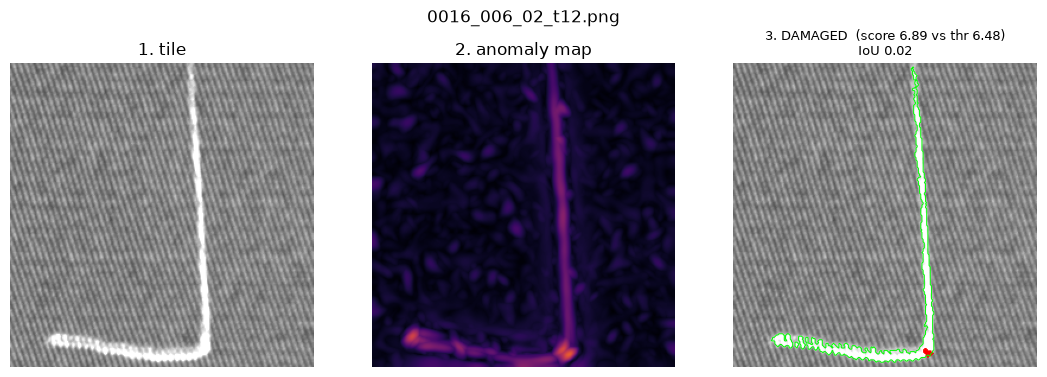

smallest defect: 0025_019_02_t10.png, 8 px


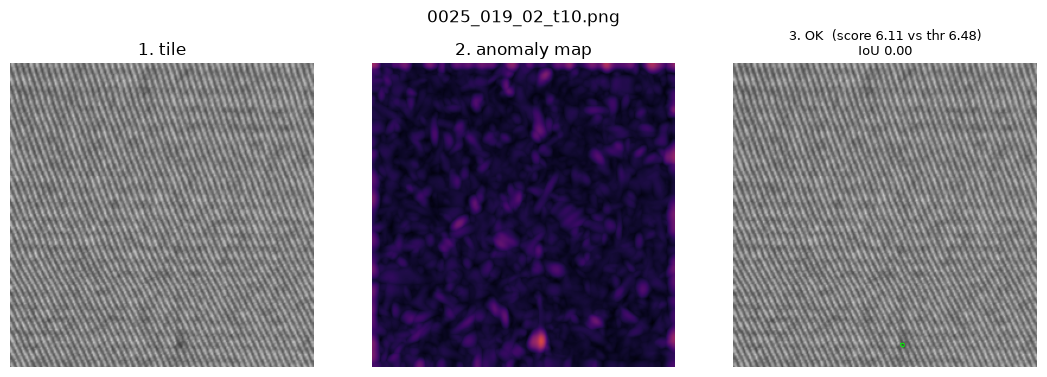

good tile: 0020_000_02_t15.png


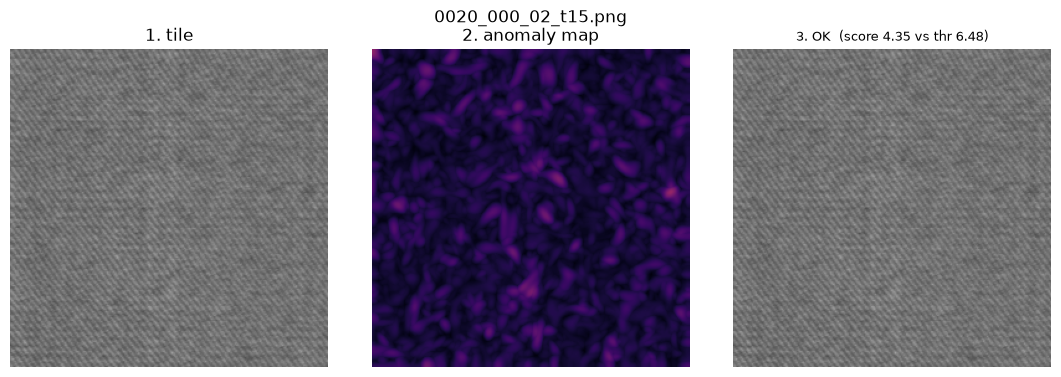

In [6]:
E.show_examples(res)

### One example per defect type
The dataset has 12 defect types (second part of the file name), spread over different fabrics. One tile per type: the clearest one (largest mask) from the fabric with the most tiles of that type. Each is judged with the threshold of its own fabric, set from that fabric's good_cal only (other fabrics are calibrated here, so this cell takes longer). Red = detected, green = ground-truth mask.

type   fabric  tiles  example tile           area px    score      thr  result
002        01     10  0005_002_01_t08.png       2514     6.24     5.86  DAMAGED (caught)
006        02      9  0016_006_02_t12.png       2111     6.89     6.48  DAMAGED (caught)
010        03     63  0103_010_03_t12.png      19060     3.87     9.22  OK (missed)
016        03      7  0021_016_03_t14.png        823     6.79     9.22  OK (missed)
019        02     40  0023_019_02_t08.png         54     5.59     6.48  OK (missed)
022        00     12  0065_022_00_t05.png        473     5.23     6.74  OK (missed)
023        01      6  0067_023_01_t09.png        577     4.32     5.86  OK (missed)
025        03      5  0107_025_03_t05.png         24     9.13     9.22  OK (missed)
027        05      1  0094_027_05_t01.png        265     6.85     5.98  DAMAGED (caught)
029        04      2  0083_029_04_t10.png        208     7.50     7.02  DAMAGED (caught)
030        03     14  0076_030_03_t09.png        222     6.95

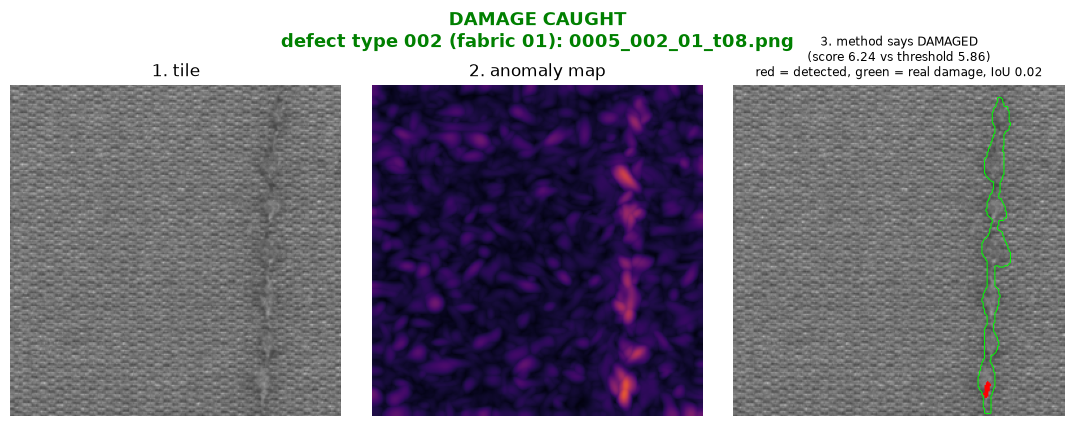

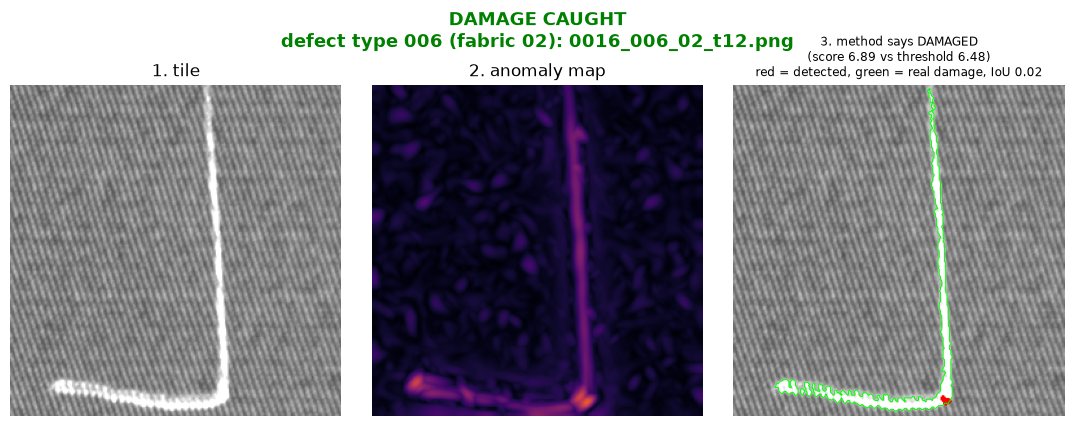

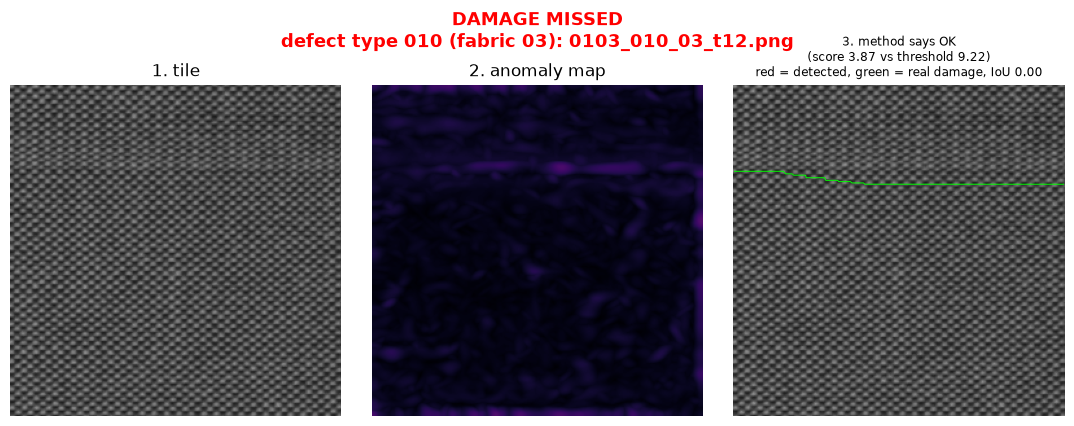

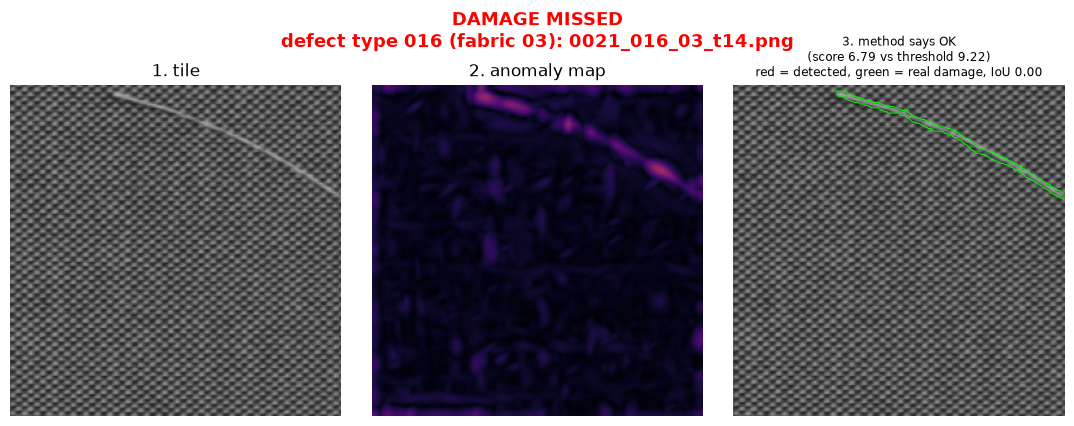

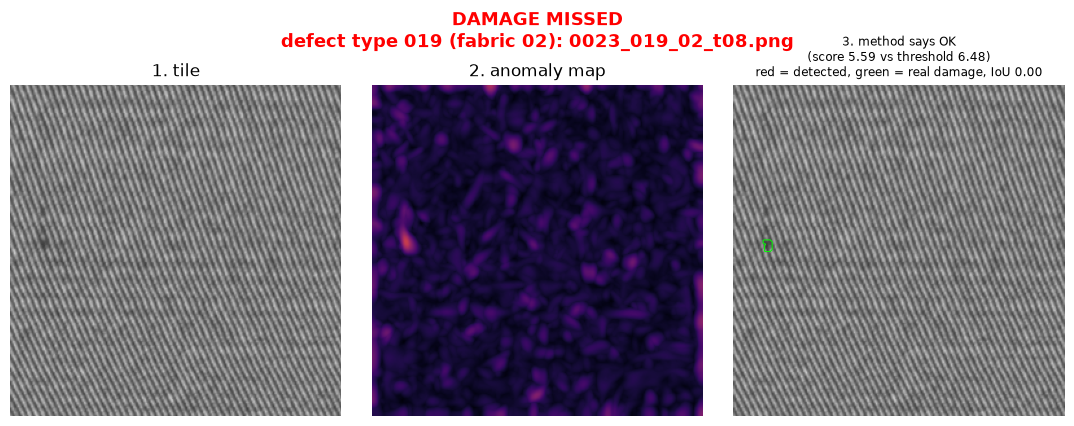

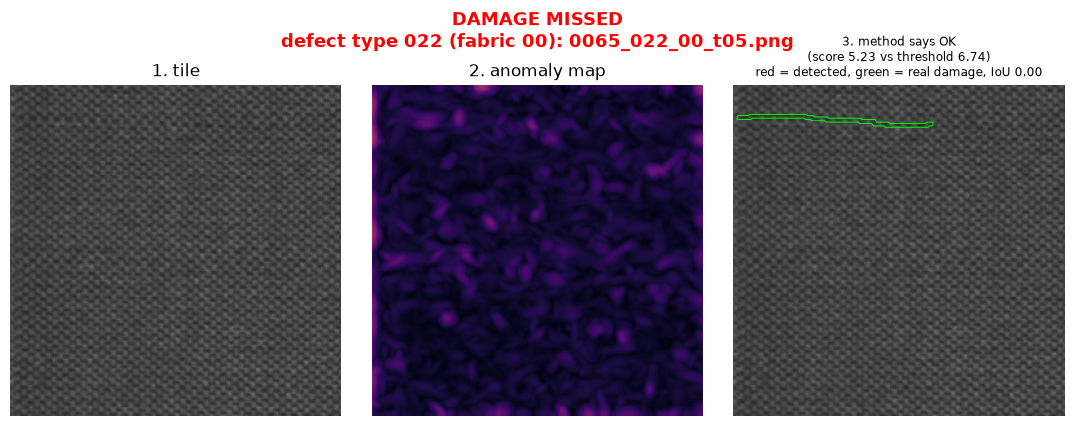

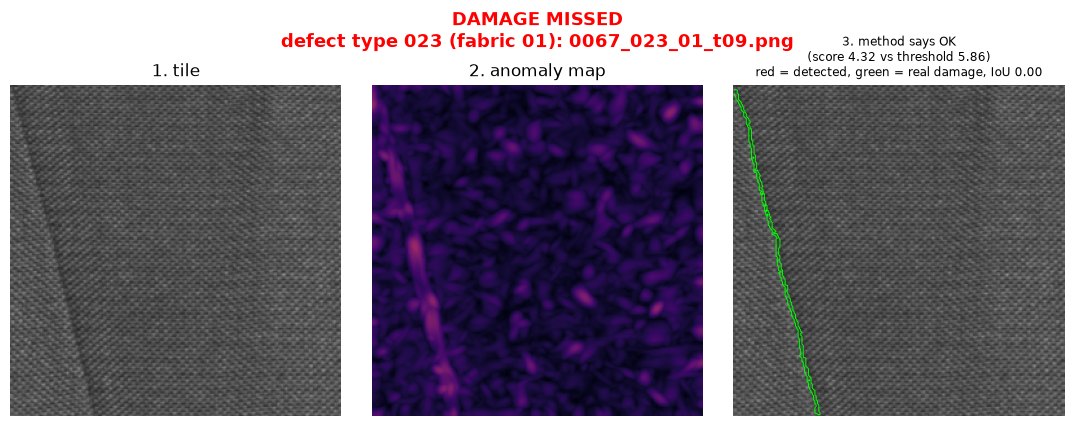

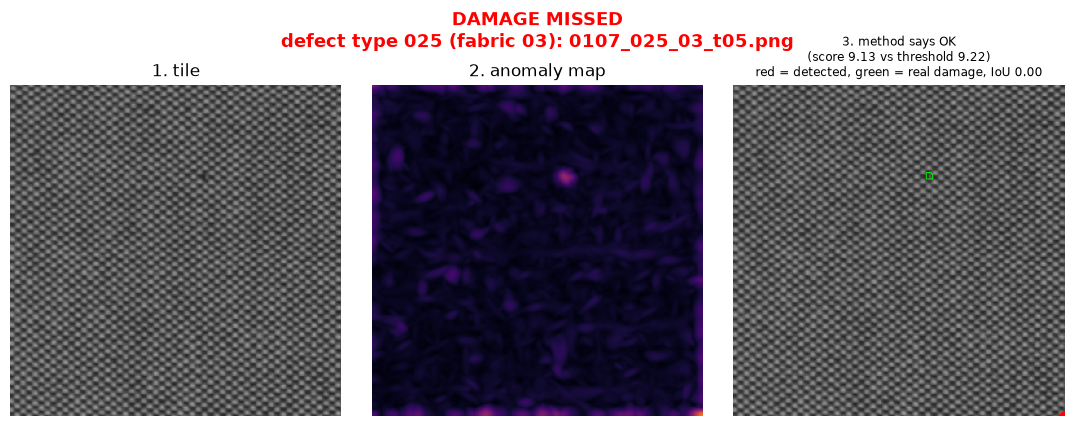

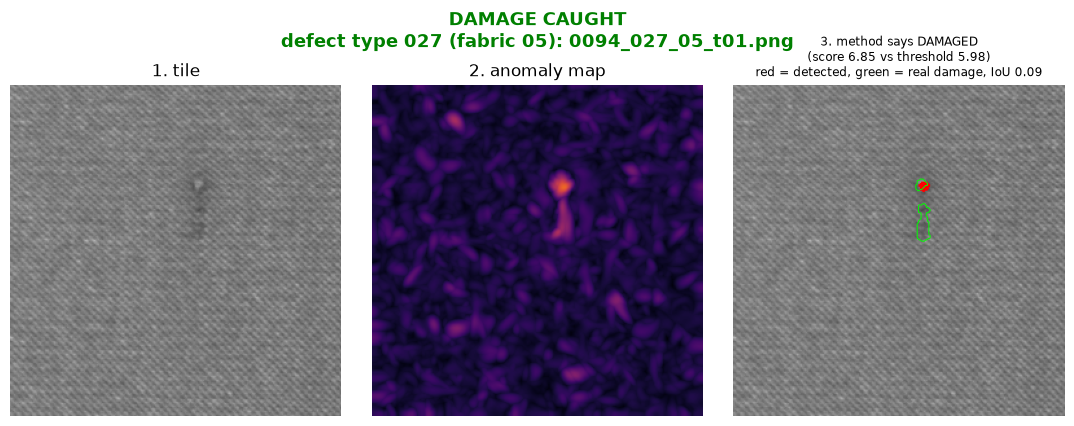

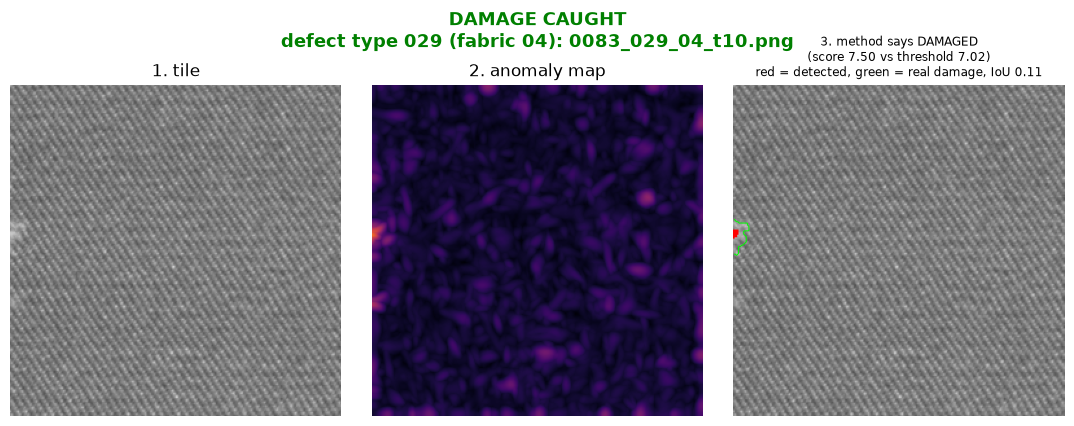

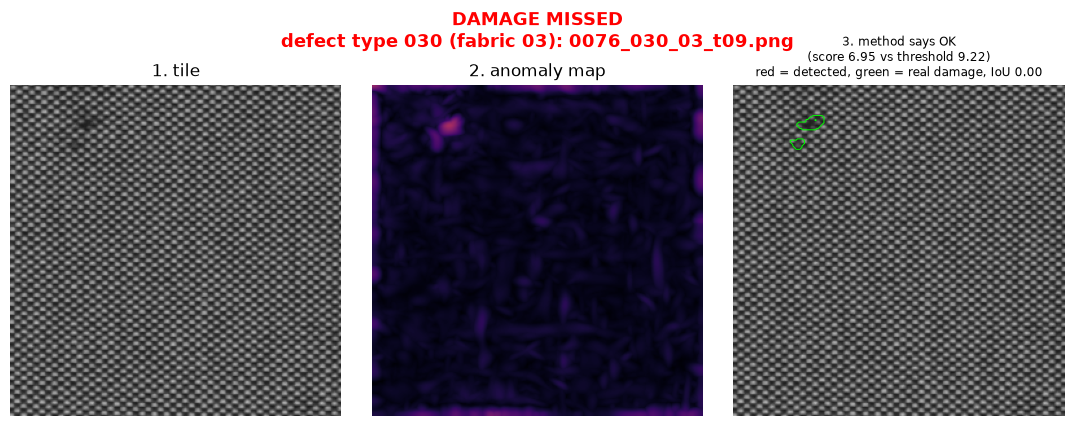

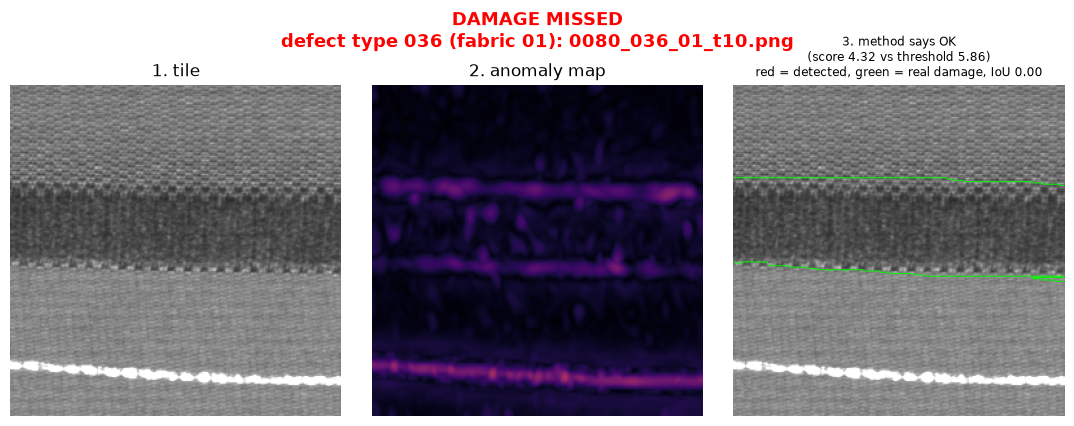

In [4]:
E.show_per_type(method, fit, res, **SETTINGS)

## All fabrics
Same method and settings on every fabric, one threshold per fabric from its own good_cal strips. Columns: FAR on good_test and on hard negatives (hn), recall overall / small / large defects, strip-level FAR and recall, AUROC, IoU, ms per tile.

In [7]:
summaries = E.all_fabrics(method, fit, METHOD_NAME, **SETTINGS)

fabric   test  hard defect    FAR  FAR hn  recall  small  large stripFAR stripRec  AUROC   IoU    ms
----------------------------------------------------------------------------------------------------
00        110    76      9   2.7%    0.0%   33.3% 100.0%  25.0%    30.0%    42.9%  0.775  0.08  38.0
01        154   146     28   0.6%    6.2%   35.7% 100.0%  30.8%     9.1%    58.3%  0.648  0.05  34.4
02        140   507     38   0.0%    1.4%   36.8%  39.1%  33.3%     0.0%    36.8%  0.893  0.11  32.7
03        110   256     89   0.0%    0.0%    0.0%   0.0%   0.0%     0.0%     0.0%  0.547  0.01  32.3
04        138   129     12   0.0%    3.1%   58.3%  80.0%  42.9%     0.0%    60.0%  0.949  0.28  32.4
05        150    13      1   0.7%    0.0%  100.0%    n/a 100.0%    10.0%   100.0%  1.000  0.09  33.7
06        143    81      7   4.9%    8.6%   42.9%  60.0%   0.0%    40.0%    50.0%  0.517  0.10  32.4
-------------------------------------------------------------------------------------------